In [127]:
import numpy as np
import pandas as pd


### Timestamp Object

Time stamps reference particular moments in time (e.g., Oct 24th, 2022 at 7:00pm)

### Creating Timestamp objects

In [128]:
# creating a timestamp
ts = pd.Timestamp('2026/10/04')
type(ts)

pandas.Timestamp

In [129]:
# variations
pd.Timestamp('2026/10/04')
pd.Timestamp('2026, 10, 04')

Timestamp('2026-10-04 00:00:00')

In [130]:
# only year
pd.Timestamp('2026')

Timestamp('2026-01-01 00:00:00')

In [131]:
# using text
pd.Timestamp('4th October 2026')

Timestamp('2026-10-04 00:00:00')

In [132]:
# providing time also
pd.Timestamp('4th October 2026 11:31AM')

Timestamp('2026-10-04 11:31:00')

In [133]:
# AM and PM

In [134]:
# using python's datetime.datetime object
import datetime as dt

x = pd.Timestamp(dt.datetime(2026, 10, 4, 11, 31, 56))
x

Timestamp('2026-10-04 11:31:56')

In [135]:
# fetching attributes
print(x.year)
print(x.month)
print(x.day)
print(x.hour)
print(x.minute)
print(x.second)

2026
10
4
11
31
56


In [136]:
# why separate objects to handle data and time when python already has datetime functionality?

- syntax wise datetime is very convenient
- But the performance takes a hit while working with huge data. List vs Numpy Array
- The weaknesses of Python's datetime format inspired the NumPy team to add a set of native time series data type to NumPy.
- The datetime64 dtype encodes dates as 64-bit integers, and thus allows arrays of dates to be represented very compactly.

In [137]:
import numpy as np
date = np.array('2015-07-04', dtype=np.datetime64)
date

array('2015-07-04', dtype='datetime64[D]')

In [138]:
date + np.arange(12)

array(['2015-07-04', '2015-07-05', '2015-07-06', '2015-07-07',
       '2015-07-08', '2015-07-09', '2015-07-10', '2015-07-11',
       '2015-07-12', '2015-07-13', '2015-07-14', '2015-07-15'],
      dtype='datetime64[D]')

- Because of the uniform type in NumPy datetime64 arrays, this type of operation can be accomplished much more quickly than if we were working directly with Python's datetime objects, especially as arrays get large 

- Pandas Timestamp object combines the ease-of-use of python datetime with the efficient storage and vectorized interface of numpy.datetime64

- From a group of these Timestamp objects, Pandas can construct a DatetimeIndex that can be used to index data in a Series or DataFrame

### DatetimeIndex Object

A collection of pandas timestamp

In [139]:
# from strings
di = pd.DatetimeIndex(['2023/1/1', '2022/1/1', '2021/1/1'])
type(di)
type(di[0])

pandas.Timestamp

In [140]:
# using python datetime object
pd.DatetimeIndex([dt.datetime(2023, 1, 1), dt.datetime(2022, 1, 1), dt.datetime(2021, 1, 1)])

DatetimeIndex(['2023-01-01', '2022-01-01', '2021-01-01'], dtype='datetime64[us]', freq=None)

In [141]:
# using pd.timestamps
dt_index = pd.DatetimeIndex([pd.Timestamp(2023, 1, 1), pd.Timestamp(2022, 1, 1), pd.Timestamp(2021, 1, 1)])

In [142]:
# using datatimeindex as series index

pd.Series([1, 2, 3], index=dt_index)

2023-01-01    1
2022-01-01    2
2021-01-01    3
dtype: int64

### date_range function

In [143]:
# generate daily dates in a given range
pd.date_range(start='2026/10/4', end='2026/10/31', freq='D')
pd.date_range(start='2026/10/4', end='2026/10/31', freq='2D')
pd.date_range(start='2026/10/4', end='2026/10/31', freq='3D')

DatetimeIndex(['2026-10-04', '2026-10-07', '2026-10-10', '2026-10-13',
               '2026-10-16', '2026-10-19', '2026-10-22', '2026-10-25',
               '2026-10-28', '2026-10-31'],
              dtype='datetime64[us]', freq='3D')

In [144]:
# alternate days in a given range
pd.date_range(start='2026/10/4', end='2026/10/31', freq='3D')

DatetimeIndex(['2026-10-04', '2026-10-07', '2026-10-10', '2026-10-13',
               '2026-10-16', '2026-10-19', '2026-10-22', '2026-10-25',
               '2026-10-28', '2026-10-31'],
              dtype='datetime64[us]', freq='3D')

In [145]:
# B -> business days
pd.date_range(start='2026/10/4', end='2026/10/31', freq='B')

DatetimeIndex(['2026-10-05', '2026-10-06', '2026-10-07', '2026-10-08',
               '2026-10-09', '2026-10-12', '2026-10-13', '2026-10-14',
               '2026-10-15', '2026-10-16', '2026-10-19', '2026-10-20',
               '2026-10-21', '2026-10-22', '2026-10-23', '2026-10-26',
               '2026-10-27', '2026-10-28', '2026-10-29', '2026-10-30'],
              dtype='datetime64[us]', freq='B')

In [146]:
# W -> one week per day
pd.date_range(start='2026/10/4', end='2026/10/31', freq='W')
pd.date_range(start='2026/10/4', end='2026/10/31', freq='W-THU')

DatetimeIndex(['2026-10-08', '2026-10-15', '2026-10-22', '2026-10-29'], dtype='datetime64[us]', freq='W-THU')

In [147]:
# h -> Hourly data(factor)
pd.date_range(start='2026/10/4', end='2026/10/31', freq='h')
pd.date_range(start='2026/10/4', end='2026/10/31', freq='6h')

DatetimeIndex(['2026-10-04 00:00:00', '2026-10-04 06:00:00',
               '2026-10-04 12:00:00', '2026-10-04 18:00:00',
               '2026-10-05 00:00:00', '2026-10-05 06:00:00',
               '2026-10-05 12:00:00', '2026-10-05 18:00:00',
               '2026-10-06 00:00:00', '2026-10-06 06:00:00',
               ...
               '2026-10-28 18:00:00', '2026-10-29 00:00:00',
               '2026-10-29 06:00:00', '2026-10-29 12:00:00',
               '2026-10-29 18:00:00', '2026-10-30 00:00:00',
               '2026-10-30 06:00:00', '2026-10-30 12:00:00',
               '2026-10-30 18:00:00', '2026-10-31 00:00:00'],
              dtype='datetime64[us]', length=109, freq='6h')

In [148]:
# ME -> Month end
pd.date_range(start='2026/10/4', end='2026/10/31', freq='ME')

DatetimeIndex(['2026-10-31'], dtype='datetime64[us]', freq='ME')

In [149]:
# MS -> Month start
pd.date_range(start='2026/10/01', end='2026/10/31', freq='MS')

DatetimeIndex(['2026-10-01'], dtype='datetime64[us]', freq='MS')

In [150]:
# YE -> Year end
pd.date_range(start='2026/10/4', end='2030/2/28', freq='YE')

DatetimeIndex(['2026-12-31', '2027-12-31', '2028-12-31', '2029-12-31'], dtype='datetime64[us]', freq='YE-DEC')

In [151]:
# using periods(number of results)
pd.date_range(start='2026/10/4', periods=25, freq='ME')
pd.date_range(start='2026/10/4', periods=25, freq='h')

DatetimeIndex(['2026-10-04 00:00:00', '2026-10-04 01:00:00',
               '2026-10-04 02:00:00', '2026-10-04 03:00:00',
               '2026-10-04 04:00:00', '2026-10-04 05:00:00',
               '2026-10-04 06:00:00', '2026-10-04 07:00:00',
               '2026-10-04 08:00:00', '2026-10-04 09:00:00',
               '2026-10-04 10:00:00', '2026-10-04 11:00:00',
               '2026-10-04 12:00:00', '2026-10-04 13:00:00',
               '2026-10-04 14:00:00', '2026-10-04 15:00:00',
               '2026-10-04 16:00:00', '2026-10-04 17:00:00',
               '2026-10-04 18:00:00', '2026-10-04 19:00:00',
               '2026-10-04 20:00:00', '2026-10-04 21:00:00',
               '2026-10-04 22:00:00', '2026-10-04 23:00:00',
               '2026-10-05 00:00:00'],
              dtype='datetime64[us]', freq='h')

### to_datetime function

converts an existing objects to pandas timestamp/datetimeindex object

In [152]:
# simple series example

s = pd.Series(['2026/1/1', '2024/1/1', '2023/1/1'])

s.str.split('/').str.get(0)

pd.to_datetime(s).dt.year
pd.to_datetime(s).dt.month
pd.to_datetime(s).dt.month_name()
pd.to_datetime(s).dt.day
pd.to_datetime(s).dt.day_name()

0    Thursday
1      Monday
2      Sunday
dtype: str

In [153]:
# with errors
s = pd.Series(['2026/1/1', '2024/1/1', '2023/130/1'])

pd.to_datetime(s, errors='coerce').dt.year
pd.to_datetime(s, errors='coerce').dt.month
pd.to_datetime(s, errors='coerce').dt.month_name()

0    January
1    January
2        NaN
dtype: str

In [154]:
df = pd.read_csv('../datasets/expense_data.csv')
df.shape

(277, 11)

In [155]:
df.head()

,Date,Account,Category,Subcategory,Note,INR,Income/Expense,Note.1,Amount,Currency,Account.1
0,3/2/2022 10:11,CUB - online payment,Food,NaN,Brownie,50.0,Expense,NaN,50.0,INR,50.0
1,3/2/2022 10:11,CUB - online payment,Other,NaN,To lended people,300.0,Expense,NaN,300.0,INR,300.0
2,3/1/2022 19:50,CUB - online payment,Food,NaN,Dinner,78.0,Expense,NaN,78.0,INR,78.0
3,3/1/2022 18:56,CUB - online payment,Transportation,NaN,Metro,30.0,Expense,NaN,30.0,INR,30.0
4,3/1/2022 18:22,CUB - online payment,Food,NaN,Snacks,67.0,Expense,NaN,67.0,INR,67.0


In [156]:
df.info()

df['Date'] = pd.to_datetime(df['Date'])

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 277 entries, 0 to 276
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Date            277 non-null    str    
 1   Account         277 non-null    str    
 2   Category        277 non-null    str    
 3   Subcategory     0 non-null      float64
 4   Note            273 non-null    str    
 5   INR             277 non-null    float64
 6   Income/Expense  277 non-null    str    
 7   Note.1          0 non-null      float64
 8   Amount          277 non-null    float64
 9   Currency        277 non-null    str    
 10  Account.1       277 non-null    float64
dtypes: float64(5), str(6)
memory usage: 40.7 KB
<class 'pandas.DataFrame'>
RangeIndex: 277 entries, 0 to 276
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Date            277 non-null    datetime64[us]
 1   Account         2

### dt accessor

Accessor object for datetimelike properties of the Series values.

In [157]:
df['Date'].dt.year
df['Date'].dt.month
df['Date'].dt.month_name()
df['Date'].dt.day_name()
df['Date'].dt.is_month_end
df['Date'].dt.is_quarter_end
df['Date'].dt.is_quarter_start

0      False
1      False
2      False
3      False
4      False
       ...  
272    False
273    False
274    False
275    False
276    False
Name: Date, Length: 277, dtype: bool

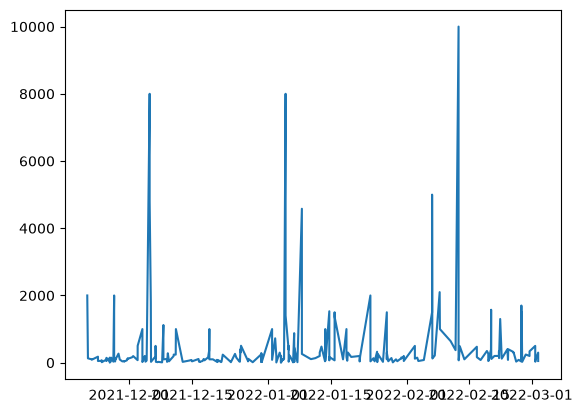

In [158]:
# plot graph
import matplotlib.pyplot as plt
plt.plot(df['Date'], df['INR'])
plt.show()

In [159]:
# day name wise bar chart/month wise bar chart

df['day_name'] = df['Date'].dt.day_name()
df.head()

,Date,Account,Category,Subcategory,Note,INR,Income/Expense,Note.1,Amount,Currency,Account.1,day_name
0,2022-03-02 10:11:00,CUB - online payment,Food,NaN,Brownie,50.0,Expense,NaN,50.0,INR,50.0,Wednesday
1,2022-03-02 10:11:00,CUB - online payment,Other,NaN,To lended people,300.0,Expense,NaN,300.0,INR,300.0,Wednesday
2,2022-03-01 19:50:00,CUB - online payment,Food,NaN,Dinner,78.0,Expense,NaN,78.0,INR,78.0,Tuesday
3,2022-03-01 18:56:00,CUB - online payment,Transportation,NaN,Metro,30.0,Expense,NaN,30.0,INR,30.0,Tuesday
4,2022-03-01 18:22:00,CUB - online payment,Food,NaN,Snacks,67.0,Expense,NaN,67.0,INR,67.0,Tuesday


<Axes: xlabel='day_name'>

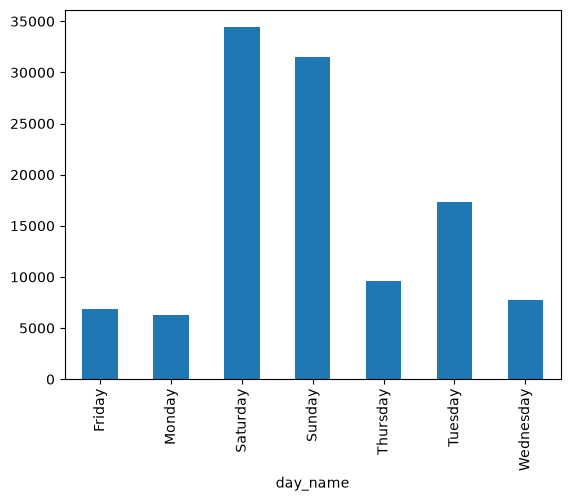

In [160]:
df.groupby('day_name')['INR'].sum().plot(kind='bar')
df.groupby('day_name')['INR'].mean().plot(kind='bar')

In [161]:
df['month_name'] = df['Date'].dt.month_name()
df.head()

,Date,Account,Category,Subcategory,Note,INR,Income/Expense,Note.1,Amount,Currency,Account.1,day_name,month_name
0,2022-03-02 10:11:00,CUB - online payment,Food,NaN,Brownie,50.0,Expense,NaN,50.0,INR,50.0,Wednesday,March
1,2022-03-02 10:11:00,CUB - online payment,Other,NaN,To lended people,300.0,Expense,NaN,300.0,INR,300.0,Wednesday,March
2,2022-03-01 19:50:00,CUB - online payment,Food,NaN,Dinner,78.0,Expense,NaN,78.0,INR,78.0,Tuesday,March
3,2022-03-01 18:56:00,CUB - online payment,Transportation,NaN,Metro,30.0,Expense,NaN,30.0,INR,30.0,Tuesday,March
4,2022-03-01 18:22:00,CUB - online payment,Food,NaN,Snacks,67.0,Expense,NaN,67.0,INR,67.0,Tuesday,March


<Axes: xlabel='month_name'>

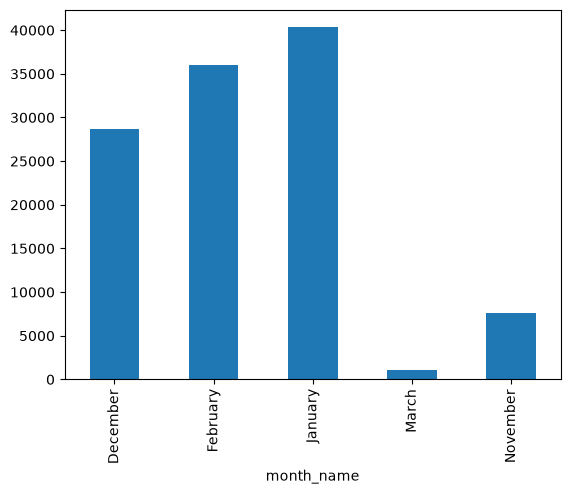

In [162]:
df.groupby('month_name')['INR'].sum().plot(kind='bar')

In [163]:
df[df['Date'].dt.is_month_end]

,Date,Account,Category,Subcategory,Note,INR,Income/Expense,Note.1,Amount,Currency,Account.1,day_name,month_name
7,2022-02-28 11:56:00,CUB - online payment,Food,NaN,Pizza,339.15,Expense,NaN,339.15,INR,339.15,Monday,February
8,2022-02-28 11:45:00,CUB - online payment,Other,NaN,From kumara,200.00,Income,NaN,200.00,INR,200.00,Monday,February
61,2022-01-31 08:44:00,CUB - online payment,Transportation,NaN,Vnr to apk,50.00,Expense,NaN,50.00,INR,50.00,Monday,January
62,2022-01-31 08:27:00,CUB - online payment,Other,NaN,To vicky,200.00,Expense,NaN,200.00,INR,200.00,Monday,January
63,2022-01-31 08:26:00,CUB - online payment,Transportation,NaN,To ksr station,153.00,Expense,NaN,153.00,INR,153.00,Monday,January
242,2021-11-30 14:24:00,CUB - online payment,Gift,NaN,Bharath birthday,115.00,Expense,NaN,115.00,INR,115.00,Tuesday,November
243,2021-11-30 14:17:00,CUB - online payment,Food,NaN,Lunch with company,128.00,Expense,NaN,128.00,INR,128.00,Tuesday,November
244,2021-11-30 10:11:00,CUB - online payment,Food,NaN,Breakfast,70.00,Expense,NaN,70.00,INR,70.00,Tuesday,November
